<div style="background:#0d1117;border-radius:10px;padding:20px 30px;margin-bottom:6px;display:flex;align-items:center;justify-content:space-between;gap:40px;flex-wrap:wrap;">
  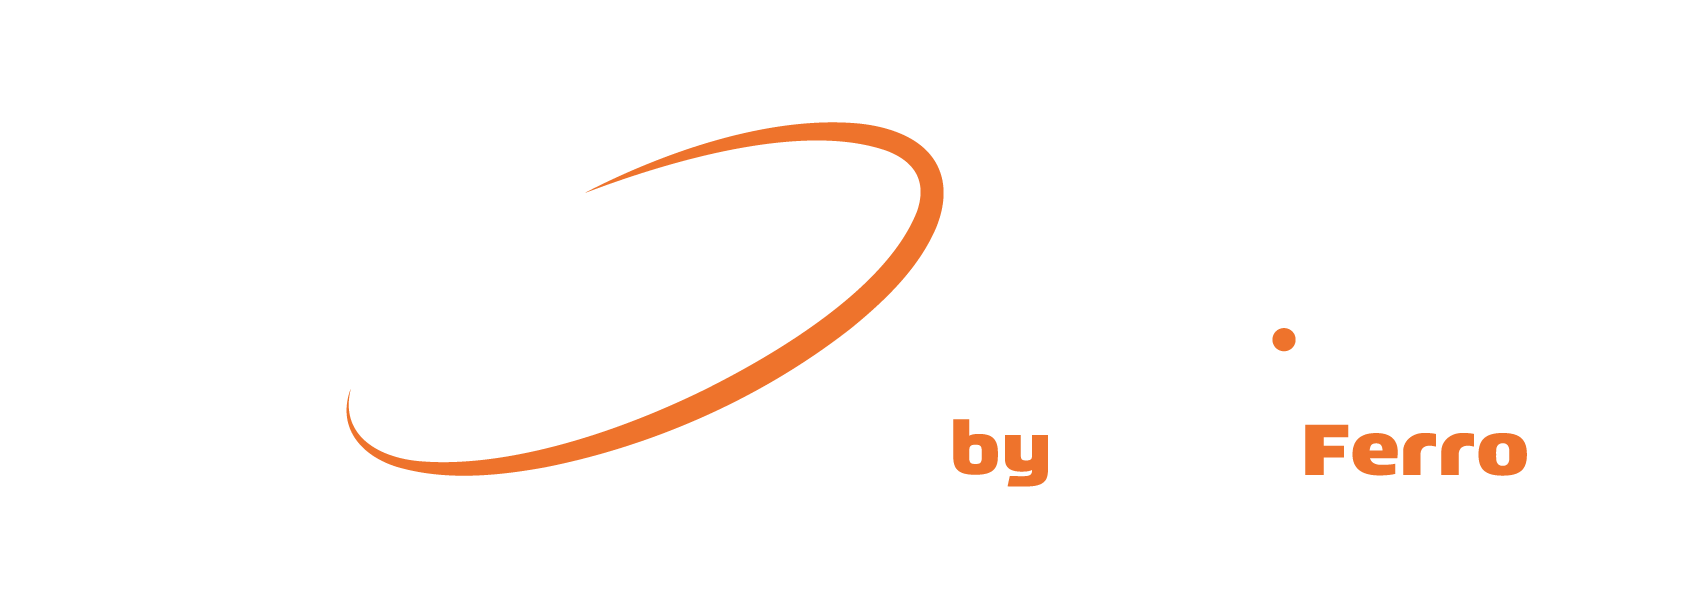
  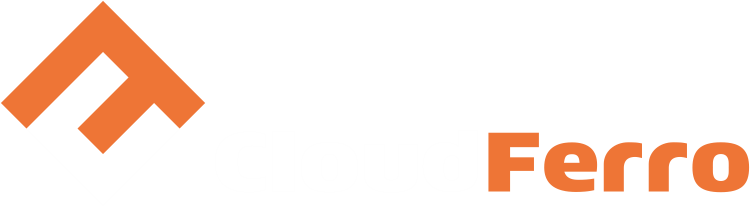
</div>

# ESD Embeddings: PCA and change detection at a point

Explores ESD land-representation embeddings at one point of interest, across years.

Archive: `/eodata/geoAI-embeddings/Embeddings-Seamless-Data/ESD-Embeddings/SDC30_EBD_V001`
Global coverage, 30 m pixels, one layer per year from 2000 to 2024.

**Steps**

1. Find the Sentinel-2 MGRS tile holding the point, and which years exist for it.
2. Read a window around the point instead of the whole 337 MB tile.
3. Split the 13 bands into 12 embedding dimensions plus an observation count.
4. Reduce the embedding to 3 components with PCA and show it as RGB.
5. Measure change between consecutive years and mark hotspots.
6. Cluster with KMeans to compare land-cover-like classes over time.
7. Map cosine similarity to the point: where else looks like here.

Set `AOI_LAT`, `AOI_LON` and `YEARS` in the configuration cell. The rest runs by itself.

## Running on CREODIAS

Runs on a CREODIAS VM with `/eodata` mounted. Source files are read in place, nothing is downloaded or copied.

The archive sits on object storage behind that mount, which occasionally returns I/O errors or reports files as zero bytes. Every read below retries, which is why the helpers look more defensive than usual. Without `/eodata` mounted the notebook cannot load anything.

## Setup

In [ ]:
# OPTIONAL: only needed if the imports below fail (e.g. `ModuleNotFoundError` or an
# `attr`/`attrs` conflict). Uncomment the block, run this cell on its own, then restart
# the kernel before running the rest of the notebook.
# import subprocess, sys
# subprocess.run([
#     sys.executable, "-m", "pip", "install", "--user", "-q",
#     "numpy==2.2.6", "matplotlib==3.10.9", "scikit-learn==1.7.2",
#     "rasterio==1.4.4", "affine==3.0.0", "attrs>=22",
# ], check=True)
# print("Installed. Restarting kernel...")
#
# import IPython
# IPython.get_ipython().kernel.do_shutdown(restart=True)
# print("Kernel restarted. Run the notebook from the top.")

In [ ]:
import json
import os
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

import rasterio
from rasterio.errors import RasterioIOError
from rasterio.windows import Window
from affine import Affine
from rasterio.warp import transform as warp_transform

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
plt.rcParams["figure.facecolor"] = "white"

## Configuration

In [ ]:
AOI_LAT = 22.23     # e.g. Warsaw
AOI_LON = 11.01

# Years to compare; change detection runs between consecutive entries.
# The archive holds 2000 to 2024. None = use every year found for the resolved tile,
# which is 25 windows to read and a much heavier PCA/KMeans fit.
YEARS = [2000, 2012, 2024]

# Analysis window centred on the AOI, in pixels. 1 px = 30 m, so 512 px = 15.4 km.
# The full tile is 3600 px; raising this costs read time and memory.
WINDOW_PX = 224

# Pixels built from fewer than this many observations are treated as invalid.
MIN_OBS = 1

# Cap on the number of pixel-years used to fit PCA and KMeans. Keeps the fit quick
# when the window is large or many years are selected; None fits on everything.
FIT_SAMPLE = 100_000

DATA_ROOT = "/eodata/geoAI-embeddings/Embeddings-Seamless-Data/ESD-Embeddings/SDC30_EBD_V001"
PRODUCT = "SDC30_EBD_V001"

# Local cache. /eodata drops out for minutes at a time, so once a window has been read
# it is kept here and reruns never touch the mount again. Delete the folder to refresh.
CACHE_DIR = "esd_cache"
USE_CACHE = True

# How long to keep retrying a cold mount before giving up, in seconds. Outages usually
# clear inside a few minutes, so waiting beats making you rerun the cell yourself.
MOUNT_WAIT_SECONDS = 240

# Years to probe for. Widen it if the archive grows past this.
YEAR_RANGE = range(2000, 2031)

print(f"Point: lat={AOI_LAT}, lon={AOI_LON}")
print(f"Window: {WINDOW_PX} px = {WINDOW_PX * 30 / 1000:.1f} km across")

## Finding the tile

ESD uses the Sentinel-2 MGRS grid, so the tile name comes from the 100 km MGRS square holding the point: UTM zone, latitude band letter, then the column and row letters.

Plain arithmetic is not quite enough:

- Tiles are 108 km wide but named after 100 km squares, so they overlap, and some reach into the next UTM zone or latitude band. A point near a boundary can sit in a tile whose name does not match its computed square.
- The archive has gaps, mostly over water, and MGRS has special cases around Norway and Svalbard.

So the function returns candidates in order, best guess first, and the next cell takes the first one that exists and actually contains the point.

In [ ]:
MGRS_COLS = ["ABCDEFGH", "JKLMNPQR", "STUVWXYZ"]   # column letters, by zone modulo 3
MGRS_ROWS = "ABCDEFGHJKLMNPQRSTUV"                  # row letters, 20-letter cycle
MGRS_BANDS = "CDEFGHJKLMNPQRSTUVWX"                 # latitude bands, 8° each, from 80°S


def utm_epsg(lat, zone):
    return (32600 if lat >= 0 else 32700) + zone


def tile_candidates(lat, lon):
    """MGRS tile names that may contain the point, best guess first."""
    zone0 = int((lon + 180) // 6) + 1
    band0 = min(int((lat + 80) // 8), 19)
    names = []

    for dz in (0, -1, 1):
        zone = ((zone0 - 1 + dz) % 60) + 1
        try:
            xs, ys = warp_transform("EPSG:4326", f"EPSG:{utm_epsg(lat, zone)}", [lon], [lat])
        except Exception:
            continue
        easting, northing = xs[0], ys[0]
        if northing < 0:
            northing += 10_000_000          # southern hemisphere false northing

        col_idx = int(easting // 100_000) - 1
        if not 0 <= col_idx < 8:
            continue                        # point is outside this zone's 100 km columns
        col = MGRS_COLS[(zone - 1) % 3][col_idx]
        row = MGRS_ROWS[(int(northing // 100_000) + (0 if zone % 2 else 5)) % 20]

        for db in (0, -1, 1):
            band = band0 + db
            if 0 <= band < 20:
                name = f"{zone:02d}{MGRS_BANDS[band]}{col}{row}"
                if name not in names:
                    names.append(name)
    return names


def tile_neighbours(lat, lon):
    """Tiles sharing an edge with the point's own MGRS square, in the same UTM zone.

    Sentinel-2 tiles are 108 km wide but named after 100 km squares, so they overlap by
    about 8 km. A point just inside one tile's edge usually sits well inside its neighbour,
    which gives a better centred window.
    """
    zone = int((lon + 180) // 6) + 1
    band0 = min(int((lat + 80) // 8), 19)
    xs, ys = warp_transform("EPSG:4326", f"EPSG:{utm_epsg(lat, zone)}", [lon], [lat])
    easting, northing = xs[0], ys[0]
    if northing < 0:
        northing += 10_000_000
    col_idx = int(easting // 100_000) - 1
    row_idx = int(northing // 100_000) + (0 if zone % 2 else 5)

    names = []
    for dc, dr in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        ci = col_idx + dc
        if not 0 <= ci < 8:
            continue
        col = MGRS_COLS[(zone - 1) % 3][ci]
        row = MGRS_ROWS[(row_idx + dr) % 20]
        # a row neighbour can fall in the next latitude band, a column neighbour cannot
        for db in ((0,) if dr == 0 else (0, dr)):
            band = band0 + db
            if 0 <= band < 20:
                name = f"{zone:02d}{MGRS_BANDS[band]}{col}{row}"
                if name not in names:
                    names.append(name)
    return names


def tile_file(tile, year):
    return os.path.join(DATA_ROOT, str(year), f"{PRODUCT}_{tile}_{year}.tif")


def file_present(path):
    """The /eodata mount answers `exists` with True for any path, so test the size instead."""
    try:
        return os.path.getsize(path) > 0
    except OSError:
        return False


def aoi_tag():
    return f"{AOI_LAT:+.4f}_{AOI_LON:+.4f}_w{WINDOW_PX}".replace(".", "p").replace("+", "")


def cache_get(name):
    """Cached artefact, or None. Never raises: a broken cache must not break the run."""
    path = os.path.join(CACHE_DIR, name)
    if not (USE_CACHE and os.path.isfile(path)):
        return None
    try:
        if name.endswith(".json"):
            with open(path, encoding="utf-8") as fh:
                return json.load(fh)
        return np.load(path)
    except Exception:
        return None


def cache_put(name, value):
    if not USE_CACHE:
        return
    try:
        os.makedirs(CACHE_DIR, exist_ok=True)
        path = os.path.join(CACHE_DIR, name)
        if name.endswith(".json"):
            with open(path, "w", encoding="utf-8") as fh:
                json.dump(value, fh)
        else:
            np.save(path, value)
    except Exception:
        pass          # a cache that cannot be written is a missed optimisation, not an error


def open_safely(path, retries=12, delay=0.8):
    """/eodata is backed by object storage and can be flaky, so back off and retry on open."""
    last_err = None
    for attempt in range(retries):
        try:
            return rasterio.open(path)
        except RasterioIOError as e:
            last_err = e
            time.sleep(delay * (attempt + 1))
    raise last_err


CANDIDATES = tile_candidates(AOI_LAT, AOI_LON)
print("Candidate tiles, best guess first:", ", ".join(CANDIDATES))

### Which tile, which years

Takes the first candidate that has files and contains the point, then checks whether an overlapping neighbour holds the same point further from its own edge, which centres the window better.

The probe is wrapped in a retry loop. The mount swings between reporting correct file sizes and reporting zero for everything, so one cold pass finding nothing is not proof that a tile is missing.

In [ ]:
# Identifying a tile does not need its year list: one readable layer settles it.
# Enumerating every year for every candidate on every retry fired hundreds of requests
# at a mount that was already struggling, which slowed recovery down instead of helping.
PROBE_YEARS = list(YEARS) if YEARS else [2024, 2012, 2000]


def identify(name):
    """Distance in pixels from the point to this tile's nearest edge, or None.

    None means the tile has no readable layer right now, or it does not hold the point.
    The margin is what decides whether a window around the point has to be clipped.
    """
    for year in PROBE_YEARS:
        if not file_present(tile_file(name, year)):
            continue
        try:
            with open_safely(tile_file(name, year), retries=4) as ds:
                xs, ys = warp_transform("EPSG:4326", ds.crs, [AOI_LON], [AOI_LAT])
                row, col = ds.index(xs[0], ys[0])
                height, width = ds.height, ds.width
        except RasterioIOError:
            continue              # mount hiccup, not a verdict on this candidate
        if 0 <= row < height and 0 <= col < width:
            return min(row, col, height - 1 - row, width - 1 - col), year
        return None               # a real tile, just not the one holding this point
    return None


def years_present(name, wanted, budget=None):
    """Which of `wanted` this tile has, re-probing only the ones that came back missing.

    Runs on the tile we already confirmed exists, so every wanted year genuinely is in
    the archive (2000 to 2024, no gaps) -- a year that comes back missing is the mount
    flickering, never a real absence. Uses the same patience budget as resolving the
    tile itself: the old 3-pass / ~2s version gave up on a mount hiccup almost instantly,
    which is why a run could settle for one lucky year and drop the other two for good.
    """
    deadline = time.time() + (MOUNT_WAIT_SECONDS if budget is None else budget)
    found, missing = [], list(wanted)
    attempt = 0
    while missing:
        still = []
        for year in missing:
            (found if file_present(tile_file(name, year)) else still).append(year)
        missing = still
        if not missing:
            break
        attempt += 1
        remaining = deadline - time.time()
        if remaining <= 0:
            print(f"  gave up waiting for {missing} after {MOUNT_WAIT_SECONDS}s")
            break
        pause = min(5.0 * attempt, 30.0, remaining)
        print(f"  {missing}: not readable yet, waiting {pause:.0f}s "
              f"({remaining:.0f}s of patience left)")
        time.sleep(pause)
    return sorted(found)


def resolve_tile(budget=None):
    """First candidate that is readable and really contains the point.

    Keeps trying until the patience budget runs out rather than after a fixed handful of
    passes: mount outages last minutes, and a cell that gives up in twenty seconds just
    hands the waiting back to you.
    """
    deadline = time.time() + (MOUNT_WAIT_SECONDS if budget is None else budget)
    attempt = 0
    while True:
        for name in CANDIDATES:
            hit = identify(name)
            if hit is not None:
                return name, hit[0], hit[1]
        attempt += 1
        remaining = deadline - time.time()
        if remaining <= 0:
            return None, 0, None
        pause = min(5.0 * attempt, 30.0, remaining)
        print(f"  attempt {attempt}: nothing readable yet, waiting {pause:.0f}s "
              f"({remaining:.0f}s of patience left)")
        time.sleep(pause)


GEOM_KEY = f"geom_{aoi_tag()}.json"
GEOM = cache_get(GEOM_KEY)

if GEOM:
    TILE, MARGIN, PROVEN_YEAR = GEOM["tile"], GEOM["margin"], GEOM.get("proven_year")
    print(f"Tile {TILE} restored from {CACHE_DIR}, /eodata not consulted.")
else:
    TILE, MARGIN, PROVEN_YEAR = resolve_tile()


def candidates_in_listing(names):
    """Which candidates the archive actually holds, judged by directory listing.

    Worth the extra call only on the failure path, but it is the authoritative answer:
    the mount will list a tile whose own file size it reports as zero, so a listing
    separates "not in the archive" from "the mount will not serve this object today".
    Returns None when no year directory can be read at all.
    """
    for year in sorted(YEAR_RANGE, reverse=True):
        try:
            entries = os.listdir(os.path.join(DATA_ROOT, str(year)))
        except OSError:
            continue
        if not entries:
            continue
        present = {e.split("_")[3] for e in entries if e.endswith(".tif") and e.count("_") >= 4}
        return sorted(set(names) & present)
    return None


if TILE is None:
    listed = candidates_in_listing(CANDIDATES)
    if listed is None:
        raise RuntimeError(
            f"/eodata is not answering: no year directory under {DATA_ROOT} could be read.\n"
            "Nothing is wrong with your coordinates. The mount drops out for anything from "
            "seconds to about ten minutes and recovers on its own, so wait and rerun."
        )
    if listed:
        raise RuntimeError(
            f"The archive does contain {', '.join(listed)} for lat={AOI_LAT}, lon={AOI_LON}, "
            "but the mount would not serve the file after several retries.\n"
            "That is a transient /eodata failure, not missing data. Wait a moment and rerun."
        )
    raise RuntimeError(
        f"No ESD tile found for lat={AOI_LAT}, lon={AOI_LON}.\n"
        f"Tried: {', '.join(CANDIDATES)}\n"
        "The archive lists none of them, so the tile really is absent. Coverage is land "
        "only, so check the point is not over open water."
    )

# The point can land near a tile edge, where the window would be clipped. Overlapping
# neighbours often hold the same ground further from their own edge. Skipped on a cache
# hit: the tile is already settled, and probing neighbours would reach for /eodata again.
if not GEOM and MARGIN < WINDOW_PX // 2:
    print(f"{TILE}: AOI sits {MARGIN} px from the edge, checking overlapping neighbours")
    for name in tile_neighbours(AOI_LAT, AOI_LON):
        alt = identify(name)
        if alt is not None and alt[0] > MARGIN:
            TILE, MARGIN, PROVEN_YEAR = name, alt[0], alt[1]
            print(f"  {name} holds it {MARGIN} px from the edge, using that instead")

WANTED = list(YEARS) if YEARS else list(YEAR_RANGE)
CACHED_YEARS = [y for y in WANTED if cache_get(f"win_{TILE}_{y}_{aoi_tag()}.npy") is not None]

# Cached years are available no matter what the mount says. The rest are still probed, so
# the cache fills up over successive runs instead of freezing at whatever the first run
# managed to grab. Once every wanted year is cached the mount is not touched at all.
MISSING = [y for y in WANTED if y not in CACHED_YEARS]
AVAILABLE_YEARS = sorted(set(CACHED_YEARS) | set(years_present(TILE, MISSING) if MISSING else []))

if CACHED_YEARS:
    print(f"From cache: {CACHED_YEARS}" + (f", still asking /eodata for {MISSING}" if MISSING else ""))

# identify() already opened PROVEN_YEAR on this tile, so a mount flicker during the year
# probe must not discard a layer we have demonstrably read.
if PROVEN_YEAR is not None and (YEARS is None or PROVEN_YEAR in YEARS):
    AVAILABLE_YEARS = sorted(set(AVAILABLE_YEARS) | {PROVEN_YEAR})

print(f"Tile: {TILE}")
print(f"AOI is {MARGIN} px ({MARGIN * 30 / 1000:.1f} km) from the nearest tile edge")

if YEARS is None:
    print(f"Years present for this tile: {AVAILABLE_YEARS}")
    YEARS = list(AVAILABLE_YEARS)
else:
    missing = [y for y in YEARS if y not in AVAILABLE_YEARS]
    YEARS = [y for y in YEARS if y in AVAILABLE_YEARS]
    if missing:
        print(f"Requested but not readable right now, dropped: {missing}")

if not YEARS:
    raise RuntimeError(
        f"Tile {TILE} was found, but none of the requested years came back.\n"
        f"The probe saw: {AVAILABLE_YEARS or 'no years at all'}.\n"
        "Every tile in this archive holds 2000 to 2024, so an incomplete list means the "
        "mount dropped out mid-probe rather than the data being missing. Rerun this cell."
    )

print(f"Years used: {YEARS}")
if len(YEARS) < 2:
    print(
        "\nOnly one year selected, so the change-detection and hotspot steps will be "
        "skipped. The PCA, clustering and similarity steps all run normally."
    )


## Sanity check

Checks one tile before loading anything: band count, dtype, CRS, resolution. The last band is not part of the embedding. It counts how many observations went into each pixel that year, and is used here as a validity mask.

The 12 embedding bands are `uint16` with no scale or offset in the metadata and no companion scale file, so they are divided by 65535 to land in [0, 1]. That is the same constant for every band, so PCA, cluster assignments and relative distances are unaffected. Only the absolute units of the change maps depend on it.

In [ ]:
if GEOM and GEOM.get("n_bands_file"):
    N_BANDS_FILE = GEOM["n_bands_file"]
    N_BANDS = N_BANDS_FILE - 1
    OBS_BAND = N_BANDS_FILE
    print(f"Metadata restored from {CACHE_DIR}, /eodata not consulted.")
    print(f"Bands in file: {N_BANDS_FILE}  ->  {N_BANDS} embedding + 1 observation count")
    print(f"CRS: {GEOM['crs']}  (UTM zone of tile {TILE})")
    sample_ds = None
else:
    sample_path = tile_file(TILE, YEARS[0])
    print(f"File: {sample_path}")
    try:
        sample_ds = open_safely(sample_path)
    except RasterioIOError as e:
        raise RuntimeError(
            f"Could not open {sample_path} after several retries. This is a mount or data "
            f"availability problem, not a problem with the coordinates.\nUnderlying error: {e}"
        )

if sample_ds is not None:
    N_BANDS_FILE = sample_ds.count
    N_BANDS = N_BANDS_FILE - 1      # embedding bands; the last band is the observation count
    OBS_BAND = N_BANDS_FILE

    print(f"Bands in file: {N_BANDS_FILE}  ->  {N_BANDS} embedding + 1 observation count")
    print(f"dtype: {sample_ds.dtypes[0]}")
    print(f"CRS: {sample_ds.crs}  (UTM zone of tile {TILE})")
    print(f"Resolution (CRS units/px): {sample_ds.res}")
    print(f"Tile size: {sample_ds.height} x {sample_ds.width} px "
          f"= {sample_ds.height * sample_ds.res[1] / 1000:.0f} x "
          f"{sample_ds.width * sample_ds.res[0] / 1000:.0f} km")
    print(f"Tile bounds: {sample_ds.bounds}")

    # Check the last band looks like a small-integer count, not an embedding band.
    probe = sample_ds.read(OBS_BAND, window=Window(0, 0, 256, 256))
    if probe.max() > 1000:
        print(f"\nWARNING: band {OBS_BAND} reaches {probe.max()}, which does not look like "
              "an observation count. Check the product spec before trusting the mask.")
    else:
        print(f"\nBand {OBS_BAND} sample range: {probe.min()} to {probe.max()} observations, "
              "consistent with a per-pixel observation count.")

    sample_ds.close()

## Load the window for each year

The window is computed once and the same pixels are read for every year, so the years line up without resampling. If the point sits near a tile edge the window is clamped to stay inside the raster and will not be perfectly centred.

In [ ]:
def window_for_point(ds, lat, lon, size):
    xs, ys = warp_transform("EPSG:4326", ds.crs, [lon], [lat])
    row, col = ds.index(xs[0], ys[0])
    width = min(size, ds.width)
    height = min(size, ds.height)
    col_off = int(np.clip(col - width // 2, 0, ds.width - width))
    row_off = int(np.clip(row - height // 2, 0, ds.height - height))
    return Window(col_off, row_off, width, height), (row - row_off, col - col_off)


# Geometry is identical for every year of a tile, so it is cached and the mount is only
# consulted the first time an AOI is analysed.
AOI_WINDOW = None
if GEOM and GEOM.get("window"):
    col_off, row_off, win_w, win_h = GEOM["window"]
    AOI_WINDOW = Window(col_off, row_off, win_w, win_h)
    AOI_PIXEL = tuple(GEOM["aoi_pixel"])
    AOI_CRS = rasterio.crs.CRS.from_string(GEOM["crs"])
    AOI_TRANSFORM = Affine(*GEOM["transform"])
else:
    for year in YEARS:
        try:
            with open_safely(tile_file(TILE, year)) as ds:
                AOI_WINDOW, AOI_PIXEL = window_for_point(ds, AOI_LAT, AOI_LON, WINDOW_PX)
                AOI_TRANSFORM = ds.window_transform(AOI_WINDOW)
                AOI_CRS = ds.crs
                N_BANDS_FILE = ds.count
            break
        except RasterioIOError:
            print(f"  {year}: could not open, trying the next year for the window geometry")

    if AOI_WINDOW is None:
        raise RuntimeError(
            f"Could not open any year of tile {TILE} within {MOUNT_WAIT_SECONDS}s. "
            "The mount is down; rerun when it recovers."
        )
    cache_put(GEOM_KEY, {
        "tile": TILE, "margin": MARGIN, "proven_year": PROVEN_YEAR,
        "window": [int(AOI_WINDOW.col_off), int(AOI_WINDOW.row_off),
                   int(AOI_WINDOW.width), int(AOI_WINDOW.height)],
        "aoi_pixel": [int(AOI_PIXEL[0]), int(AOI_PIXEL[1])],
        "crs": str(AOI_CRS), "transform": list(AOI_TRANSFORM)[:6],
        "n_bands_file": int(N_BANDS_FILE),
    })

print(f"Window: {AOI_WINDOW}")
print(f"AOI at pixel (row, col) = {AOI_PIXEL} within the window")


def load_window(year):
    """The raw window for one year, from the local cache when it is already there."""
    key = f"win_{TILE}_{year}_{aoi_tag()}.npy"
    raw = cache_get(key)
    if raw is None:
        path = tile_file(TILE, year)
        try:
            ds = open_safely(path)
        except RasterioIOError as e:
            raise RuntimeError(f"{year}: could not open {path}.\nUnderlying error: {e}")
        with ds:
            if str(ds.crs) != str(AOI_CRS):
                raise RuntimeError(f"{year}: CRS {ds.crs} does not match {AOI_CRS}.")
            raw = ds.read(window=AOI_WINDOW)
        cache_put(key, raw)
    else:
        print(f"  {year}: from cache")

    embedding = raw[:N_BANDS].astype(np.float32) / 65535.0   # uint16 -> [0, 1]
    n_obs = raw[OBS_BAND - 1]
    return embedding, n_obs


aoi_stacks = {}    # year -> (bands, H, W), embedding scaled to [0, 1]
obs_counts = {}    # year -> (H, W), observations behind each pixel
skipped = []

for year in YEARS:
    print(f"Loading {year}...")
    try:
        emb, n_obs = load_window(year)
    except RuntimeError as e:
        # The mount fails transiently often enough that dropping a year beats aborting.
        print(f"  skipped: {e}")
        skipped.append(year)
        continue
    aoi_stacks[year] = emb
    obs_counts[year] = n_obs
    print(f"  shape: {emb.shape}, observations per pixel: {n_obs.min()} to {n_obs.max()}")

YEARS = [y for y in YEARS if y not in skipped]
if not YEARS:
    raise RuntimeError(f"Every year failed to load for tile {TILE}. The mount is failing; rerun.")
if skipped:
    print(f"\nDropped after repeated read failures: {skipped}. Rerun this cell to retry them.")

H, W = aoi_stacks[YEARS[0]].shape[1:]

# A pixel is usable only if every year has enough observations for it.
VALID = np.ones((H, W), dtype=bool)
for year in YEARS:
    VALID &= obs_counts[year] >= MIN_OBS

print(f"\nWindow shape (bands, H, W): {aoi_stacks[YEARS[0]].shape}")
print(f"Valid pixels (>= {MIN_OBS} obs in every year): {VALID.sum()} / {VALID.size} "
      f"({100 * VALID.mean():.1f}%)")

## Observation count

How many clear observations went into each pixel that year. It varies with cloud cover and latitude, and it is the quickest way to see where the embedding rests on thin evidence. Zero means nothing usable, and those pixels are dropped from everything below.

In [ ]:
fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS), 4.5), squeeze=False)
axes = axes[0]

vmax_obs = max(int(obs_counts[y].max()) for y in YEARS)
for ax, y in zip(axes, YEARS):
    im = ax.imshow(obs_counts[y], cmap="viridis", vmin=0, vmax=vmax_obs)
    ax.set_title(f"{y}: observations/pixel\nmedian {np.median(obs_counts[y]):.0f}")
    ax.plot(AOI_PIXEL[1], AOI_PIXEL[0], "r+", markersize=12, markeredgewidth=2, label="AOI")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].legend(loc="upper right", fontsize=8, framealpha=0.85)
fig.suptitle("Observations behind each embedding pixel", y=1.03)
plt.tight_layout()
plt.show()

## PCA composite per year

PCA is fit once across all years, so colours are comparable between panels: a colour shift means the embedding actually changed, not that the axes rotated. Only valid pixels are used for the fit.

**The red cross marks your AOI**, the point set by `AOI_LAT` and `AOI_LON`. It appears on every map below.

In [ ]:
all_pixels = np.concatenate(
    [aoi_stacks[y].reshape(N_BANDS, -1).T[VALID.ravel()] for y in YEARS], axis=0
)

if FIT_SAMPLE and all_pixels.shape[0] > FIT_SAMPLE:
    rng = np.random.default_rng(0)
    idx = rng.choice(all_pixels.shape[0], FIT_SAMPLE, replace=False)
    fit_pixels = all_pixels[idx]
    print(f"Fitting on a random {FIT_SAMPLE} of {all_pixels.shape[0]} pixel-years "
          f"x {N_BANDS} dims (raise FIT_SAMPLE to use all)")
else:
    fit_pixels = all_pixels
    print(f"Fitting on {fit_pixels.shape[0]} pixel-years x {N_BANDS} dims")

n_components = min(3, N_BANDS)
pca = PCA(n_components=n_components)
pca.fit(fit_pixels)
print(f"Explained variance (PC1..PC{n_components}): {pca.explained_variance_ratio_}")
print(f"Cumulative: {pca.explained_variance_ratio_.sum():.3f}")


def to_rgb(pixels_pca, valid):
    """Scale PCA components to [0,1] per channel using percentile clipping over valid pixels."""
    out = np.zeros_like(pixels_pca)
    for c in range(pixels_pca.shape[-1]):
        chan = pixels_pca[..., c]
        lo, hi = np.percentile(chan[valid], [2, 98])
        out[..., c] = np.clip((chan - lo) / max(hi - lo, 1e-6), 0, 1)
    out[~valid] = 0.0
    return out


pca_rgb_per_year = {}
for y in YEARS:
    px = aoi_stacks[y].reshape(N_BANDS, -1).T
    px_pca = pca.transform(px).reshape(H, W, n_components)
    if n_components < 3:
        px_pca = np.repeat(px_pca, 3, axis=-1)[..., :3]
    pca_rgb_per_year[y] = to_rgb(px_pca, VALID)

fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS), 4.5), squeeze=False)
axes = axes[0]
for ax, y in zip(axes, YEARS):
    ax.imshow(pca_rgb_per_year[y])
    ax.plot(AOI_PIXEL[1], AOI_PIXEL[0], "r+", markersize=12, markeredgewidth=2, label="AOI")
    ax.set_title(f"{y}: PCA RGB")
    ax.axis("off")
axes[0].legend(loc="upper right", fontsize=8, framealpha=0.85)
fig.suptitle(f"ESD embedding, PCA composite per year (tile {TILE}, 30 m)", y=1.03)
plt.tight_layout()
plt.show()

## Change detection

Euclidean distance between embedding vectors at each pixel, for consecutive years. A high value means the pixel changed a lot: land cover, construction, deforestation, flooding.

Needs at least two years. If only one survives loading, the cell says so and skips.

In [ ]:
year_pairs = list(zip(YEARS[:-1], YEARS[1:]))
change_maps = {}

if not year_pairs:
    print(f"Only one year available ({YEARS[0]}), so there is nothing to difference. "
          "Skipping change detection and hotspots.")
else:
    for y0, y1 in year_pairs:
        diff = aoi_stacks[y1] - aoi_stacks[y0]
        magnitude = np.linalg.norm(diff, axis=0)
        magnitude[~VALID] = np.nan
        change_maps[(y0, y1)] = magnitude

    n_pairs = len(year_pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 4.5), squeeze=False)
    axes = axes[0]

    vmax = np.nanpercentile(np.concatenate([m.ravel() for m in change_maps.values()]), 99)
    for ax, (y0, y1) in zip(axes, year_pairs):
        im = ax.imshow(change_maps[(y0, y1)], cmap="magma", vmin=0, vmax=vmax)
        ax.set_title(f"Change {y0} → {y1}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle("Embedding change magnitude (L2 norm of the difference)", y=1.03)
    plt.tight_layout()
    plt.show()

### Change hotspots

In [ ]:
CHANGE_PERCENTILE = 95  # pixels above this percentile are flagged as significant change

if not change_maps:
    print("No change maps to threshold: at least two years are needed.")
else:
    n_pairs = len(year_pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 4.5), squeeze=False)
    axes = axes[0]

    for ax, (y0, y1) in zip(axes, year_pairs):
        mag = change_maps[(y0, y1)]
        thresh = np.nanpercentile(mag, CHANGE_PERCENTILE)
        mask = np.nan_to_num(mag, nan=-1) >= thresh

        ax.imshow(pca_rgb_per_year[y1])
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [1, 0, 0, 0.55]
        ax.imshow(overlay)
        ax.set_title(f"Hotspots {y0}→{y1} (top {100 - CHANGE_PERCENTILE}%)")
        ax.axis("off")

    fig.suptitle("Highest-change areas, overlaid on the PCA composite", y=1.03)
    plt.tight_layout()
    plt.show()

## Clustering

KMeans fit across all years so the labels stay consistent, then applied year by year. Useful for spotting where a place switched cluster, for example vegetation to built-up.

In [ ]:
N_CLUSTERS = 6

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
kmeans.fit(fit_pixels)

cmap = plt.get_cmap("tab10", N_CLUSTERS)

fig, axes = plt.subplots(1, len(YEARS), figsize=(4.5 * len(YEARS), 4.5), squeeze=False)
axes = axes[0]

cluster_maps = {}
for ax, y in zip(axes, YEARS):
    px = aoi_stacks[y].reshape(N_BANDS, -1).T
    labels = kmeans.predict(px).reshape(H, W).astype(float)
    labels[~VALID] = np.nan
    cluster_maps[y] = labels
    im = ax.imshow(labels, cmap=cmap, vmin=-0.5, vmax=N_CLUSTERS - 0.5)
    ax.plot(AOI_PIXEL[1], AOI_PIXEL[0], "r+", markersize=12, markeredgewidth=2, label="AOI")
    ax.set_title(f"{y}: clusters (k={N_CLUSTERS})")
    ax.axis("off")

cbar = fig.colorbar(im, ax=axes, ticks=range(N_CLUSTERS), fraction=0.02, pad=0.02)
cbar.set_label("cluster")
axes[0].legend(loc="upper right", fontsize=8, framealpha=0.85)
fig.suptitle("Embedding clusters (shared KMeans model across years)", y=1.03)
plt.show()

for y in YEARS:
    lab = cluster_maps[y][VALID]
    counts = np.bincount(lab.astype(int), minlength=N_CLUSTERS)
    share = 100 * counts / counts.sum()
    print(f"{y}: " + "  ".join(f"c{i}={share[i]:5.1f}%" for i in range(N_CLUSTERS)))

## Similarity to the AOI pixel

Cosine similarity between the embedding at your point and every other pixel in the window. This is what an embedding answers most directly: where else looks like here. It needs only one year, so it works whatever you set in `YEARS`.

In [ ]:
fig, axes = plt.subplots(1, len(YEARS), figsize=(4.8 * len(YEARS), 4.5), squeeze=False)
axes = axes[0]

for ax, y in zip(axes, YEARS):
    stack = aoi_stacks[y]
    ref = stack[:, AOI_PIXEL[0], AOI_PIXEL[1]]

    flat = stack.reshape(N_BANDS, -1)
    norms = np.linalg.norm(flat, axis=0) * np.linalg.norm(ref)
    sim = (flat * ref[:, None]).sum(axis=0) / np.maximum(norms, 1e-9)
    sim = sim.reshape(H, W)
    sim[~VALID] = np.nan

    im = ax.imshow(sim, cmap="viridis")
    ax.plot(AOI_PIXEL[1], AOI_PIXEL[0], "r+", markersize=12, markeredgewidth=2, label="AOI")
    ax.set_title(f"{y}: cosine similarity to AOI")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].legend(loc="upper right", fontsize=8, framealpha=0.85)
fig.suptitle("Where else in the window resembles the point", y=1.03)
plt.tight_layout()
plt.show()

<div style="background:#0d1117;border-radius:10px;padding:16px 30px;margin-top:10px;display:flex;align-items:center;justify-content:space-between;gap:40px;flex-wrap:wrap;">
  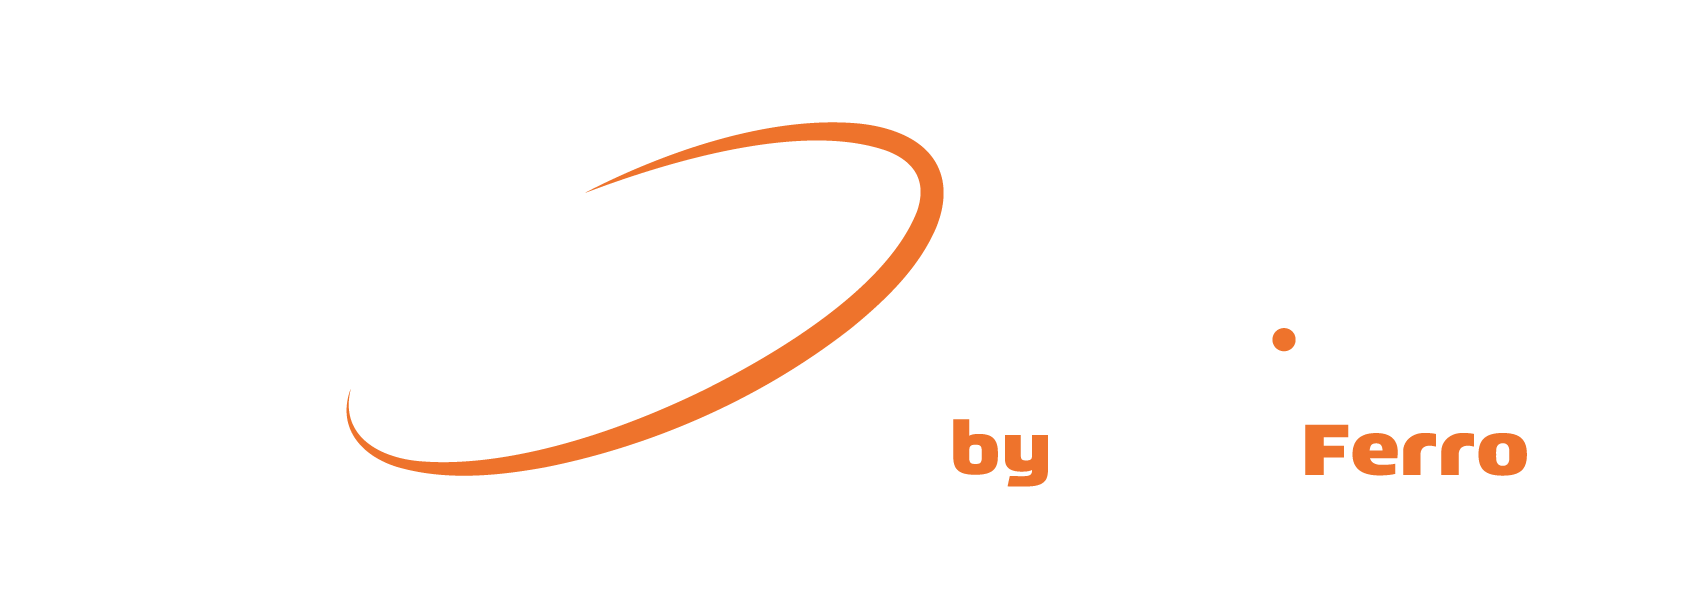
  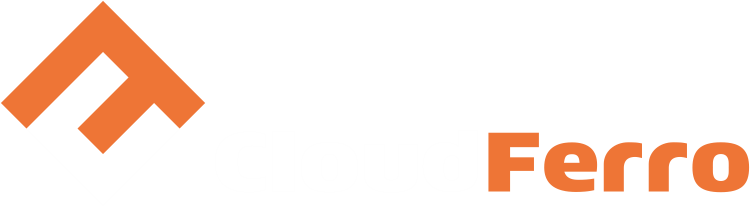
</div>

Run on [CREODIAS](https://creodias.eu), an Earth observation platform by [CloudFerro](https://cloudferro.com). The archive is mounted read only at `/eodata` on every CREODIAS virtual machine, so this notebook reads the source files in place.